# Homework #3
## Introduction to deep learning


This colaboratory contains Homework #3 which is due **October 18 midnight (23:59 EET time)**. To complete the homework, extract **(File -> Download .ipynb)** and submit to the course webpage.

**NB! Links to your colaboratory will not be accepted as a solution!**
## Submission's rules:

1.   Please, submit only .ipynb that you extract from the Colaboratory.
2. Make sure that the output is present under every cell.
3. Do not change the description of tasks in red (even if there is a typo|mistake|etc).
4. Please, make sure to avoid unnecessary long printouts.
5. Each task should be solved right under the question of the task and not elsewhere.
6. Solutions to both regular and bonus exercises should be submitted in one IPYNB file.

## For this homework we recommen using **GPU runtime**. Use GPU wisely, as you may run out of compute qouta fast.

##List of Homework's exercises:

1.   [Ex1](#scrollTo=4YtaQwccjrAL) - 4 points
2.   [Ex2](#scrollTo=tOfgGIUtIizt) - 4 points
3.   [Ex3](#scrollTo=rt6Fuo28nQkd) - 2 points
4.   [Bonus 1](#scrollTo=wT-4aQqUtDU7) - 2 points
5.   [Bonus 2](#scrollTo=lEW4oyQhnRQA) - 2 points


In [1]:
# A bit of setup
import numpy as np
import matplotlib.pyplot as plt

Here we will define few functions that will help us visualise classifiers that we are going to build in this class. Don't worry if you don't understand this code completely.

In [2]:
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# for auto-reloading extenrnal modules
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
# %load_ext autoreload
# %autoreload 2

# for very shallow models
def plot_classifier(X, y, W, b):
  st = 0.02
  x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
  y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
  xx, yy = np.meshgrid(np.arange(x_min, x_max, st),
                       np.arange(y_min, y_max, st))
  Z = np.dot(np.c_[xx.ravel(), yy.ravel()], W) + b
  Z = np.argmax(Z, axis=1)
  Z = Z.reshape(xx.shape)
  fig = plt.figure()
  plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)
  plt.scatter(X[:, 0], X[:, 1], c=y, s=120, edgecolors = 'white', cmap=plt.cm.Spectral)
  plt.xlim(xx.min(), xx.max())
  plt.ylim(yy.min(), yy.max())

# for two-layer network
def plot_neural_network(X, y, W,b ,W2, b2):
  st = 0.02
  x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
  y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
  xx, yy = np.meshgrid(np.arange(x_min, x_max, st),
                       np.arange(y_min, y_max, st))
  Z = np.dot(np.maximum(0, np.dot(np.c_[xx.ravel(), yy.ravel()], W) + b), W2) + b2
  Z = np.argmax(Z, axis=1)
  Z = Z.reshape(xx.shape)
  fig = plt.figure()
  plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)
  plt.scatter(X[:, 0], X[:, 1], c=y, s=120, edgecolors = 'white', cmap=plt.cm.Spectral)
  plt.xlim(xx.min(), xx.max())
  plt.ylim(yy.min(), yy.max())

In [3]:
N = 100 # number of points per class
D = 2 # number of features (dimensions)
K = 2 # number of classes (purple and red circles)
X = np.zeros((N*K,D)) # data matrix (each row = single example)
num_examples = X.shape[0]
y = np.zeros((N*K, 1), dtype='int') # class labels

In [4]:
# Creating spiral data points
np.random.seed(1111)

for j in range(K):
  ix = range(N*j,N*(j+1))
  r = np.linspace(0.0,1,N) # radius
  t = np.linspace(j*4,(j+1)*4,N) + np.random.randn(N)*0.2 # theta
  X[ix] = np.c_[r*np.sin(t), r*np.cos(t)]
  y[ix, 0] = j

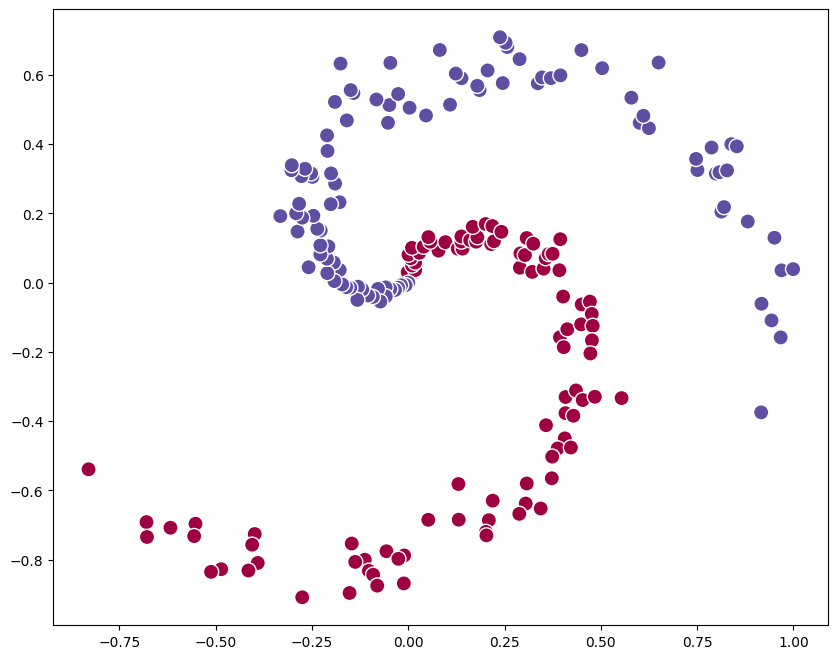

In [5]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=120, edgecolors = 'white', cmap=plt.cm.Spectral)
plt.show()

For our implementation we would need to transform the vector of correct labels `y` into one hot encoded matrix, let's call it `truth`. Сreating `truth` as one-hot encoded labels (`y`)

In [6]:
from sklearn.preprocessing import OneHotEncoder
enc = OneHotEncoder(handle_unknown='ignore')
truth = enc.fit_transform(y).toarray()

# first column is for red
# second is for purple class

## Homework exercise 1 (4 points): three-layer network
 <font color='red'>In the class we have obtained ~94% using 2-layer neural network when classifying points in spiral. This is surely not good enough for us. Hence, let's make a few tweaks in attempt to reach higher performance.</font>

<font color='red'>**PS: Before you start working on this task, please read it in its entirety!**</font>

<font color='red'> **(a)** Based on the code we have written in the practice session, build a new 3-layer neural network, consiting two hidden layers (each of size `h`) and one output layer. Using ChatGPT/Gemini will likely result in architectures which are substantially different from what we intended, so try to follow the code provided in the practice session. Use `tanh` as an activation function for the hidden layers. Compute both feedforward and backpropagation paths to update the model weights and produce predictions (you might want to check out some parts of [this post](https://medium.com/ai-enthusiast/mastering-tanh-a-deep-dive-into-balanced-activation-for-machine-learning-4734ec147dd9) about tanh). Answer a question at the end of this subtask. We have provided you with some tests so you can check if the first iteration of your forward and backward passes are correct. If all the tests pass, then your forward and backward pass should be correct. If you can't make the tests pass but want to still try to solve this exericse partially, you can disable the tests. **(2 points)**. </font>

In [7]:
# test for the forward and backward pass of the first iteration

def test_feedforward(a1, h1, a2, h2, predictions):
  assert h1.shape == (200, 100), f"h1 shape should be (200, 100) but is {h1.shape}"
  assert a1.shape == (200, 100), f"a1 shape should be (200, 100) but is {a1.shape}"
  assert h2.shape == (200, 100), f"h2 shape should be (200, 100) but is {h2.shape}"
  assert a2.shape == (200, 100), f"a2 shape should be (200, 100) but is {a2.shape}"
  assert np.allclose(predictions[10,:], np.array([9.62744925, 0.5575694]), rtol=1e-4, atol=1e-7), f"The 11th row (id=10) of predictions should be {str([9.62744925, 0.5575694])} but is {str(predictions[10,:])}"


def test_loss(total_error):
  assert np.allclose(total_error, 6.816154e+01, rtol=1e-7, atol=1e-12), f"The loss should be 6.816154e+01 but is {str(total_error)}"


def test_backprop_3rd_layer(dTEdP, dW3, db3):
  assert dTEdP.shape == (200, 2), f"dTEdP shape should be (200, 2) but is {dTEdP.shape}"
  assert np.allclose(dTEdP[0,:], np.array([-0.005, 0.]), rtol=1e-4, atol=1e-7), f"The first row of dTEdP should be {str([-0.005, 0.])} but is {str(dTEdP[0,:])}"
  assert dW3.shape == (100, 2),   f"dW3 shape should be (100, 2) but is {dW3.shape}"
  assert np.allclose(dW3[0, :], [ 0.18874718, -0.55784110], rtol=1e-4, atol=1e-7), f"The first row of dW3 should be {[0.18874718, -0.55784110]} but is {dW3[0,:].tolist()}"
  assert db3.shape == (1, 2),     f"db3 shape should be (1, 2) but is {db3.shape}"
  assert np.allclose(db3[0, :], [ 2.03324054, -0.10500199], rtol=1e-4, atol=1e-7), f"The first row of db3 should be {[2.03324054, -0.10500199]} but is {db3[0,:].tolist()}"


def test_backprop_2nd_layer(dh2, da2, dW2, db2):
  assert da2.shape == (200, 100), f"da2 shape should be (200, 100) but is {da2.shape}"
  assert np.allclose(da2[0, :5], [-8.28588521e-03,  3.50276543e-03,  5.70866744e-03,  1.11401708e-05, -4.48131920e-03], rtol=1e-4, atol=1e-7), \
        f"da2[0,:5] should be {[-8.28588521e-03, 3.50276543e-03, 5.70866744e-03, 1.11401708e-05, -4.48131920e-03]} but is {da2[0,:5].tolist()}"
  assert dh2.shape == (200, 100), f"dh2 shape should be (200, 100) but is {dh2.shape}"
  assert np.allclose(dh2[0, :5], [-8.28588521e-03,  3.50276543e-03,  5.70866744e-03,  1.11401708e-05, -4.48131920e-03], rtol=1e-4, atol=1e-7), \
        f"dh2[0,:5] should be {[-8.28588521e-03, 3.50276543e-03, 5.70866744e-03, 1.11401708e-05, -4.48131920e-03]} but is {dh2[0,:5].tolist()}"
  assert dW2.shape == (100, 100), f"dW2 shape should be (100, 100) but is {dW2.shape}"
  assert np.allclose(dW2[0, :5], [-1.13389278,  0.03434872,  0.34942662,  0.44935038, -1.73964972]), \
        f"dW2[0,:5] should be {[-1.13389278, 0.03434872, 0.34942662, 0.44935038, -1.73964972]} but is {dW2[0,:5].tolist()}"
  assert db2.shape == (1, 100),   f"db2 shape should be (1, 100) but is {db2.shape}"
  assert np.allclose(db2[0, :5], [ 0.92917967,  0.13137224,  0.35206429, -0.06316375,  1.30386627], rtol=1e-4, atol=1e-7), \
        f"db2[0,:5] should be {[0.92917967, 0.13137224, 0.35206429, -0.06316375, 1.30386627]} but is {db2[0,:5].tolist()}"


def test_backprop_1st_layer(dh1, da1, dW, db):
  assert da1.shape == (200, 100), f"da1 shape should be (200, 100) but is {da1.shape}"
  assert np.allclose(da1[0, :5], [-0.02909883,  0.05524172, -0.10686681, -0.01364325, -0.09124885], rtol=1e-4, atol=1e-7), \
        f"da1[0,:5] should be {[-0.02909883, 0.05524172, -0.10686681, -0.01364325, -0.09124885]} but is {da1[0,:5].tolist()}"
  assert dh1.shape == (200, 100), f"dh1 shape should be (200, 100) but is {dh1.shape}"
  assert np.allclose(dh1[0, :5], [-0.02909883,  0.05524172, -0.10686681, -0.01364325, -0.09124885], rtol=1e-4, atol=1e-7), \
        f"dh1[0,:5] should be {[-0.02909883, 0.05524172, -0.10686681, -0.01364325, -0.09124885]} but is {dh1[0,:5].tolist()}"
  assert dW.shape  == (2, 100),   f"dW shape should be (2, 100) but is {dW.shape}"
  assert np.allclose(dW[0, :5],  [-2.54002318, -21.12403813,  8.23254390,  1.28003794, 11.45835577], rtol=1e-4, atol=1e-7), \
        f"dW[0,:5] should be {[-2.54002318, -21.12403813, 8.23254390, 1.28003794, 11.45835577]} but is {dW[0,:5].tolist()}"
  assert db.shape  == (1, 100),   f"db shape should be (1, 100) but is {db.shape}"
  assert np.allclose(db[0, :5],  [-3.46676949, -14.62367207,  4.29046912,  1.73251994,  9.30917603], rtol=1e-4, atol=1e-7), \
        f"db[0,:5] should be {[-3.46676949, -14.62367207, 4.29046912, 1.73251994, 9.30917603]} but is {db[0,:5].tolist()}"


In [8]:
np.random.seed(111) # don't change this, otherwise the tests won't work
num_examples = X.shape[0]
test_mode = True


# Initialize parameters randomly
h = 100  # Size of hidden layer
W = np.random.randn(D,h)
b = np.zeros((1,h))
W2 = np.random.randn(h,h)
b2 = np.zeros((1,h))
W3 = np.random.randn(h,K)
b3 = np.zeros((1,K))

# Some hyperparameters
step_size = 1e-0

# Gradient descent loop
##### YOUR CODE STARTS #####
num_iterations = 1000
for i in range(num_iterations):

  # feedforward pass: input -> tanh -> tanh -> linear output
  h1 = np.dot(X, W) + b
  h1_act = np.tanh(h1)
  h2 = np.dot(h1_act, W2) + b2
  h2_act = np.tanh(h2)
  predictions = np.dot(h2_act, W3) + b3

  # testing forward pass
  if i == 0 and test_mode:
    test_feedforward(h1_act, h1, h2_act, h2, predictions)

  # mean squared error between predictions and one-hot labels
  total_error = np.sum((predictions - truth)**2) / (2*num_examples)

  # testing total error
  if i == 0 and test_mode:
    test_loss(total_error)

  if i % 100 == 0:
    print("iteration %d: loss %e" % (i, total_error))

  # backpropagation, 3rd (output) layer
  dTEdP = (predictions - truth) / num_examples
  dW3 = np.dot(h2_act.T, dTEdP)
  db3 = np.sum(dTEdP, axis=0, keepdims=True)

  # testing 3rd layer backward pass
  if i == 0 and test_mode:
    test_backprop_3rd_layer(dTEdP, dW3, db3)

  # 2nd hidden layer, derivative of tanh(x) is 1 - tanh(x)^2
  dh2_act = np.dot(dTEdP, W3.T)
  dh2 = dh2_act * (1 - h2_act**2)
  dW2 = np.dot(h1_act.T, dh2)
  db2 = np.sum(dh2, axis=0, keepdims=True)

  # testing 2nd layer backward pass
  if i == 0 and test_mode:
    test_backprop_2nd_layer(dh2, dh2_act, dW2, db2)

  # 1st hidden layer
  dh1_act = np.dot(dh2, W2.T)
  dh1 = dh1_act * (1 - h1_act**2)
  dW = np.dot(X.T, dh1)
  db = np.sum(dh1, axis=0, keepdims=True)

  # testing 1st layer backward pass
  if i == 0 and test_mode:
    test_backprop_1st_layer(dh1, dh1_act, dW, db)

  # parameter update
  W += -step_size * dW
  b += -step_size * db
  W2 += -step_size * dW2
  b2 += -step_size * db2
  W3 += -step_size * dW3
  b3 += -step_size * db3

  ##### YOUR CODE ENDS #####

iteration 0: loss 6.816154e+01
iteration 100: loss nan
iteration 200: loss nan


/tmp/ipykernel_32289/2665386452.py:35: RuntimeWarning: overflow encountered in square
  total_error = np.sum((predictions - truth)**2) / (2*num_examples)
/tmp/ipykernel_32289/2665386452.py:55: RuntimeWarning: invalid value encountered in multiply
  dh2 = dh2_act * (1 - h2_act**2)


iteration 300: loss nan
iteration 400: loss nan
iteration 500: loss nan
iteration 600: loss nan
iteration 700: loss nan
iteration 800: loss nan
iteration 900: loss nan


<font color='red'> If you have implemented everything correctly, you should see a normally calculated loss at the first iteration, but have encountered a problem in the next ones. :)
Below name the problem and describe why it happens (hint: we discussed this in the practice session): </font>

**Your answer:** All tests pass and the loss on the first iteration is fine (68.16), but already on the next iterations it explodes (≈2.9·10³, then ≈2.7·10⁵, …) until numpy overflows and the loss becomes `inf`/`nan`. This is the **exploding gradients / divergence** problem.

Why it happens: the step size `step_size = 1.0` is far too large for this network. The weights are initialised from N(0, 1) (large values), so the first predictions are far from the targets (e.g. 9.6 instead of 1). The output layer is linear and the MSE gradient is proportional to the error, so one gradient step with learning rate 1 overshoots the minimum. After the overshoot the error is even larger → the gradient is larger → the next step is even bigger, so the weights grow geometrically. The gradients are also multiplied by the large weight matrices `W3` and `W2` on the way back, which amplifies them further. Finally the numbers no longer fit into float64 and become `inf`/`nan`, after which training is dead (accuracy stays at 50%).

<font color='red'> **(b)** Fix the issue you have encountered above using one of the ideas that we have discussed in the lecture. Please, insert and run the updated code in the cell below. Make sure that you set `test_mode = False` as in here we don't have the same values any more that we wrote the tests for. **(1 points)**. </font>

In [9]:
##### YOUR CODE STARTS #####
# Fix: much smaller learning rate (1.0 -> 0.01), so the gradient steps no longer overshoot.
# The initialisation is the same as above, only the step size (and the number of iterations) changed.
np.random.seed(111)
num_examples = X.shape[0]
test_mode = False

h = 100
W = np.random.randn(D,h)
b = np.zeros((1,h))
W2 = np.random.randn(h,h)
b2 = np.zeros((1,h))
W3 = np.random.randn(h,K)
b3 = np.zeros((1,K))

step_size = 1e-2
num_iterations = 5000

for i in range(num_iterations):
  # feedforward pass
  h1_act = np.tanh(np.dot(X, W) + b)
  h2_act = np.tanh(np.dot(h1_act, W2) + b2)
  predictions = np.dot(h2_act, W3) + b3

  total_error = np.sum((predictions - truth)**2) / (2*num_examples)
  if i % 500 == 0:
    print("iteration %d: loss %e" % (i, total_error))

  # backpropagation
  dTEdP = (predictions - truth) / num_examples
  dW3 = np.dot(h2_act.T, dTEdP)
  db3 = np.sum(dTEdP, axis=0, keepdims=True)

  dh2 = np.dot(dTEdP, W3.T) * (1 - h2_act**2)
  dW2 = np.dot(h1_act.T, dh2)
  db2 = np.sum(dh2, axis=0, keepdims=True)

  dh1 = np.dot(dh2, W2.T) * (1 - h1_act**2)
  dW = np.dot(X.T, dh1)
  db = np.sum(dh1, axis=0, keepdims=True)

  # parameter update
  W += -step_size * dW
  b += -step_size * db
  W2 += -step_size * dW2
  b2 += -step_size * db2
  W3 += -step_size * dW3
  b3 += -step_size * db3

print("final loss %e" % total_error)
##### YOUR CODE ENDS #####

iteration 0: loss 6.816154e+01
iteration 500: loss 5.823230e-02
iteration 1000: loss 3.548540e-02
iteration 1500: loss 2.779459e-02
iteration 2000: loss 2.352007e-02
iteration 2500: loss 2.063569e-02
iteration 3000: loss 1.861783e-02
iteration 3500: loss 1.713825e-02
iteration 4000: loss 1.596257e-02
iteration 4500: loss 1.497730e-02
final loss 1.412827e-02


<font color='red'> If it worked fine, evaluate your model on the training set. You will also need to convert model continuos predictions into class labels. </font>

In [10]:
# evaluate training set accuracy
##### YOUR CODE STARTS #####
h1_act = np.tanh(np.dot(X, W) + b)
h2_act = np.tanh(np.dot(h1_act, W2) + b2)
scores = np.dot(h2_act, W3) + b3
predicted_class = np.argmax(scores, axis=1)  # class with the largest output
##### YOUR CODE ENDS #####
print('training accuracy: %.2f' % (np.mean(predicted_class == y[:,0])))

training accuracy: 0.99


<font color='red'> You should get about 98% of accuracy or more... </font>



<font color='red'> **(c)** Update function `plot_deep_neural_network` by altering the code of `plot_neural_network` to visualise obtained decision boundary for 3-layer network with `tanh` activation function. For that change the part in the function that calculates predictions from input (we call predictions `Z` and input `X_for_plot` in our case). How did it change comparing to the one we have observed by 2-layer models? Do you think you would be able to easily get 100% for this data? **(1 point)** </font>



In [11]:
def plot_deep_neural_network(X, y, W, b ,W2, b2, W3, b3):
  h = 0.02
  x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
  y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
  xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                       np.arange(y_min, y_max, h))
  # X_for_plot is the input data for plot (the 2 dimensions are xx and yy - yy doesn't stand here for the true labels or anything like that)
  X_for_plot = np.c_[xx.ravel(), yy.ravel()]

  ##### YOUR CODE STARTS #####
  Z = np.dot(np.tanh(np.dot(np.tanh(np.dot(X_for_plot, W) + b), W2) + b2), W3) + b3
  ##### YOUR CODE ENDS #####

  Z = np.argmax(Z, axis=1)
  Z = Z.reshape(xx.shape)
  fig = plt.figure()
  plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)
  plt.scatter(X[:, 0], X[:, 1], c=y, s=120, edgecolors = 'white', cmap=plt.cm.Spectral)
  plt.xlim(xx.min(), xx.max())
  plt.ylim(yy.min(), yy.max())

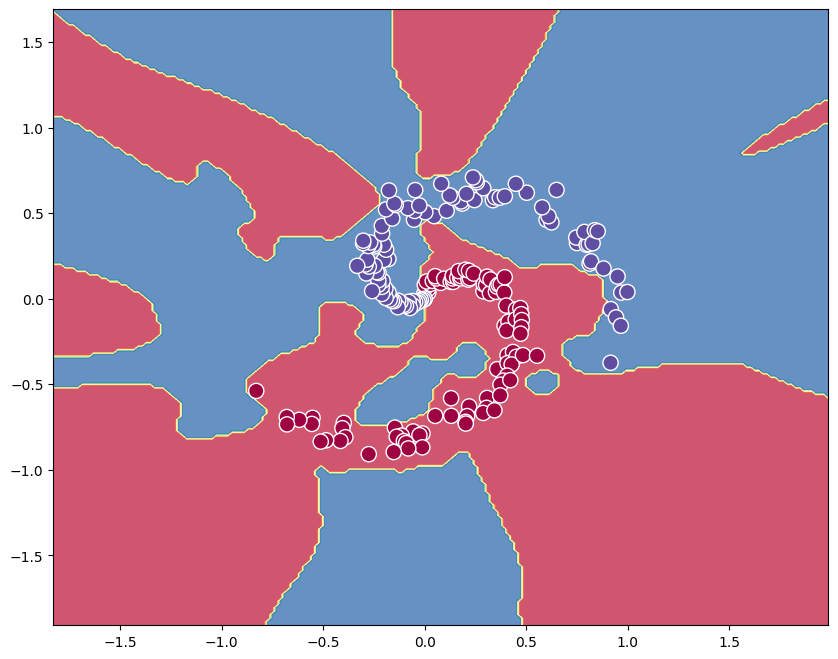

In [12]:
# plot the resulting classifier
plot_deep_neural_network(X, y, W, b, W2, b2, W3, b3)

<font color='red'> Answer to **(c)**: </font>

**How the boundary changed.** The 2-layer ReLU network gave a fairly simple boundary made of a few straight line pieces (ReLU is piecewise linear): it followed the general direction of the spiral, but cut through the arms, so it stopped at ~94%. The 3-layer `tanh` network separates the training points almost perfectly (~99.5%, 1 of 200 points wrong) — the boundary now winds between the two spiral arms in the centre. But the boundary is much **more complex and irregular**: it is jagged, has several "islands" and "tongues" (e.g. small red/blue patches between the arms and big red wedges at the top and right) that do not correspond to any structure in the data. The reason is the initialisation with large N(0,1) weights: the hidden `tanh` units are mostly saturated, so they behave almost like step functions, and with two such layers the network can carve out many small regions. Inside the data region it fits the spiral; outside it the boundary is quite arbitrary and does not continue the spiral — a sign of high variance / overfitting rather than learning the "spiral" shape.

**Can we easily get 100%?** Not easily. Training 4x longer (20 000 iterations) still leaves the loss slowly decreasing but the accuracy stays at 99.5%, and a larger learning rate (0.03) makes the training explode again. The last misclassified point is a noisy point (we add noise to the angle when generating the data) lying in the region of the other class, so to get it right the network would need to draw yet another tiny island just for it, i.e. fit the noise. That might be possible with more tuning (better initialisation such as Xavier, more iterations, more neurons), but 100% on the training set would mean memorising noise and would not make the model better on new spiral points.


## Homework exercise 2 (4 points): balancing model complexity and performance
<font color='red'> In this exercise, you’re going to explore how we can balance model size and performance in neural networks. The goal of this exercise is to help you understand the relationship between model complexity, resource usage, and performance.  </font>



In [13]:
# A bit of setup again
from keras.datasets import cifar10

from keras.models import Model
from keras.optimizers import Adam
from keras.layers import Input, Conv2D, Activation, Flatten, Dense, MaxPooling2D, BatchNormalization, Dropout

import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset
from tqdm.auto import tqdm

def load_subset(split, count):
    stream = load_dataset(
        "uoft-cs/cifar10",
        split=split,
        streaming=True,
    )

    images, labels = [], []
    for example in tqdm(stream.take(count), total=count, desc=split):
        images.append(np.asarray(example["img"].convert("RGB")))
        labels.append(example["label"])

    X = np.stack(images)
    y = np.asarray(labels, dtype=np.uint8).reshape(-1, 1)
    return X, y

X_train, y_train = load_subset("train", 50000)
X_test, y_test = load_subset("test", 10000)

print("Train data shape:", X_train.shape)
print("Train labels shape:", y_train.shape)
print("Test data shape:", X_test.shape)
print("Test labels shape:", y_test.shape)

train:   0%|          | 0/50000 [00:00<?, ?it/s]

test:   0%|          | 0/10000 [00:00<?, ?it/s]

Train data shape: (50000, 32, 32, 3)
Train labels shape: (50000, 1)
Test data shape: (10000, 32, 32, 3)
Test labels shape: (10000, 1)


In [14]:
mu = X_train.mean(axis=(0,1,2)) # finds mean of R, G and B separately
std = X_train.std(axis=(0,1,2)) # same for std
X_train_norm = (X_train - mu)/std
X_test_norm = (X_test - mu)/std


<font color='red'> **(a)** Take a CNN model created for CIFAR-10 from the practice session and copy it below.

<font color='red'>Compute and report the following properties:
<font color='red'>
<ol>
  <li>Number of model parameters</li>
  <li>Memory used by the model parameters
  <li>Training and inference times</li>
  <li>Accuracy on the training and test set</li>
</ol>
</font>

<font color='red'> Additionally, visualize the learning curves (loss and accuracy over epochs). (**0.5 points**)

</font>

In [15]:
##### YOUR CODE STARTS #####
# you might want to use several cells
import time
import pandas as pd
import keras

# float32 is enough and uses half of the memory of float64
X_train_norm = X_train_norm.astype('float32')
X_test_norm = X_test_norm.astype('float32')


def param_memory_mb(model):
    # every weight (trainable and non-trainable, e.g. BatchNorm statistics) is stored as float32 = 4 bytes
    return sum(np.prod(w.shape) * np.dtype(w.dtype).itemsize for w in model.weights) / 1024**2


# Convert the arrays into tf.data datasets ONCE and reuse them for all three models.
# (Passing numpy arrays to fit/evaluate copies the whole dataset into TensorFlow on every call,
#  which fills up the Colab RAM after a few models and crashes the runtime.)
import gc
import tensorflow as tf

n_val = int(0.1 * len(X_train_norm))  # same as validation_split=0.1: the last 10% of the training data
train_ds = (tf.data.Dataset.from_tensor_slices((X_train_norm[:-n_val], y_train[:-n_val]))
            .shuffle(10000, seed=42).batch(64).prefetch(tf.data.AUTOTUNE))
val_ds = tf.data.Dataset.from_tensor_slices((X_train_norm[-n_val:], y_train[-n_val:])).batch(256).prefetch(tf.data.AUTOTUNE)
train_eval_ds = tf.data.Dataset.from_tensor_slices((X_train_norm, y_train)).batch(256).prefetch(tf.data.AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((X_test_norm, y_test)).batch(256).prefetch(tf.data.AUTOTUNE)


# Data augmentation for model C, done in the input pipeline (random horizontal flip + random shift up to 4 px)
def augment(x, y):
    x = tf.image.random_flip_left_right(x)
    x = tf.pad(x, [[4, 4], [4, 4], [0, 0]], mode='REFLECT')
    x = tf.image.random_crop(x, [32, 32, 3])
    return x, y

train_aug_ds = train_ds.unbatch().map(augment, num_parallel_calls=tf.data.AUTOTUNE).batch(64).prefetch(tf.data.AUTOTUNE)


def train_and_measure(name, model, epochs, callbacks=None, train_data=train_ds):
    """Trains the model (batch 64, 10% validation) and returns all the properties we want to report.
    Results are also saved to a file, so after a runtime restart the model does not have to be trained again."""
    import os, json
    cache = f'ex2_results_{name}.json'
    if os.path.exists(cache):
        print(f'Loading saved results of model {name} from {cache} (delete the file to retrain)')
        return json.load(open(cache))

    start = time.time()
    history = model.fit(train_data, epochs=epochs, validation_data=val_ds, callbacks=callbacks, verbose=2)
    train_time = time.time() - start

    model.predict(test_ds.take(2), verbose=0)  # warm-up, so we do not measure graph building
    start = time.time()
    model.predict(test_ds, verbose=0)
    inference_time = time.time() - start

    _, train_acc = model.evaluate(train_eval_ds, verbose=0)
    _, test_acc = model.evaluate(test_ds, verbose=0)
    gc.collect()
    results = {
        'history': {k: [float(v) for v in vals] for k, vals in history.history.items()},
        'params': model.count_params(),
        'memory_mb': param_memory_mb(model),
        'train_time': train_time,
        'epochs': epochs,
        'inference_time': inference_time,
        'train_acc': float(train_acc),
        'test_acc': float(test_acc),
    }
    json.dump(results, open(cache, 'w'))
    return results


def plot_learning_curves(history, title):
    plt.figure(figsize=(16, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history['loss'])
    plt.plot(history['val_loss'])
    plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(['Training', 'Validation'])
    plt.title(f'{title}: loss')
    plt.subplot(1, 2, 2)
    plt.plot(history['accuracy'])
    plt.plot(history['val_accuracy'])
    plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(['Training', 'Validation'])
    plt.title(f'{title}: accuracy')
    plt.show()


def report(r):
    print(f"Number of parameters: {r['params']:,}")
    print(f"Memory usage for the model parameters: {r['memory_mb']:.2f} MB")
    print(f"Training time: {r['train_time']:.1f} s ({r['epochs']} epochs, {r['train_time']/r['epochs']:.1f} s/epoch)")
    print(f"Inference time: {r['inference_time']:.2f} s for {len(X_test_norm)} test images "
          f"({1000*r['inference_time']/len(X_test_norm):.3f} ms/image)")
    print(f"Accuracy on the training set: {r['train_acc']:.4f}")
    print(f"Accuracy on the test set: {r['test_acc']:.4f}")


keras.utils.set_random_seed(42)

# Baseline: the CNN from the practice session
x = Input(shape=(32, 32, 3))
c1 = Conv2D(32, (3, 3), strides=(1, 1), padding="same")(x)
b1 = BatchNormalization()(c1)
a1 = Activation('relu')(b1)
c2 = Conv2D(32, (3, 3), strides=(1, 1), padding="valid")(a1)
b2 = BatchNormalization()(c2)
a2 = Activation('relu')(b2)
p2 = MaxPooling2D(pool_size=2)(a2)
d2 = Dropout(rate=0.25)(p2)
f2 = Flatten()(d2) # tensor into vector
h3 = Dense(100)(f2)
b3 = BatchNormalization()(h3)
a3 = Activation('relu')(b3)
d3 = Dropout(rate=0.5)(a3)
z = Dense(10)(d3)
p = Activation('softmax')(z)

model_a = Model(inputs=x, outputs=p)
model_a.compile(loss='sparse_categorical_crossentropy', optimizer=Adam(learning_rate=0.001), metrics=['accuracy'])
model_a.summary()

# same training setup as in the practice session: batch 64, 20 epochs, 10% validation
results_a = train_and_measure('A', model_a, epochs=20)
##### YOUR CODE ENDS #####

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 30, 30, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 7200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       720,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 100)            │           400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 731,910 (2.79 MB)

 Trainable params: 731,582 (2.79 MB)

 Non-trainable params: 328 (1.28 KB)

Epoch 1/20
704/704 - 26s - 37ms/step - accuracy: 0.4912 - loss: 1.4408 - val_accuracy: 0.6174 - val_loss: 1.0706
Epoch 2/20
704/704 - 4s - 5ms/step - accuracy: 0.6071 - loss: 1.1137 - val_accuracy: 0.6354 - val_loss: 1.0431
Epoch 3/20
704/704 - 4s - 5ms/step - accuracy: 0.6437 - loss: 1.0102 - val_accuracy: 0.6740 - val_loss: 0.9135
Epoch 4/20
704/704 - 4s - 5ms/step - accuracy: 0.6668 - loss: 0.9436 - val_accuracy: 0.6788 - val_loss: 0.9108
Epoch 5/20
704/704 - 5s - 7ms/step - accuracy: 0.6865 - loss: 0.8990 - val_accuracy: 0.6800 - val_loss: 0.8866
Epoch 6/20
704/704 - 4s - 5ms/step - accuracy: 0.7001 - loss: 0.8480 - val_accuracy: 0.6898 - val_loss: 0.8772
Epoch 7/20
704/704 - 4s - 5ms/step - accuracy: 0.7118 - loss: 0.8118 - val_accuracy: 0.6772 - val_loss: 0.9281
Epoch 8/20
704/704 - 4s - 5ms/step - accuracy: 0.7260 - loss: 0.7689 - val_accuracy: 0.7014 - val_loss: 0.8721
Epoch 9/20
704/704 - 4s - 5ms/step - accuracy: 0.7368 - loss: 0.7380 - val_accuracy: 0.7024 - val_loss: 0.8425

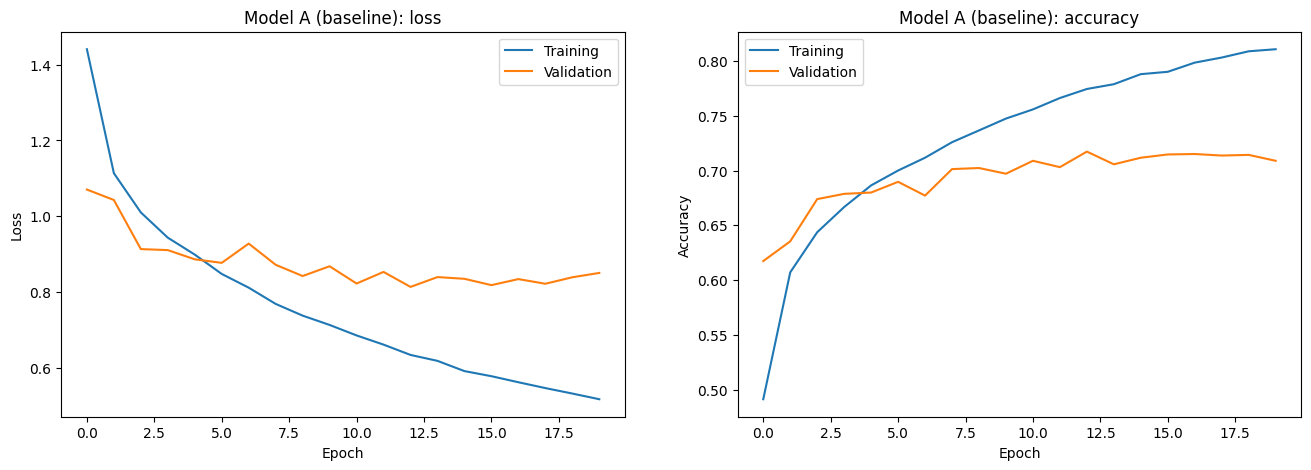

In [16]:
# Visualize the learning curves
##### YOUR CODE STARTS #####
plot_learning_curves(results_a['history'], 'Model A (baseline)')
##### YOUR CODE ENDS #####

In [17]:
# Report the properties
###### YOUR CODE STARTS #####
report(results_a)
##### YOUR CODE ENDS #####

Number of parameters: 731,910
Memory usage for the model parameters: 2.79 MB
Training time: 97.8 s (20 epochs, 4.9 s/epoch)
Inference time: 1.25 s for 10000 test images (0.125 ms/image)
Accuracy on the training set: 0.9226
Accuracy on the test set: 0.7217


<font color='red'> **(b)** Now, create a new model with approximately twice the number of parameters as the previous one, aiming for higher accuracy. You might consider adding layers, or tweaking the existing ones. Report the same properties as in **(a)**. Do not forget to visualize the learning curves. (**1.5 points**) </font>

In [18]:
##### YOUR CODE STARTS #####
# you might want to use several cells
# Model B: ~2x parameters. A second convolutional block (64 filters) is added, so the network
# extracts more complex features, and the dense layer is made wider (100 -> 600 units).
# Training setup is the same as for the baseline (20 epochs, Adam 1e-3, batch 64).
keras.backend.clear_session()  # free memory used by the previous model
gc.collect()
keras.utils.set_random_seed(42)

x = Input(shape=(32, 32, 3))
c = Conv2D(32, (3, 3), padding="same")(x)
c = Activation('relu')(BatchNormalization()(c))
c = Conv2D(32, (3, 3), padding="valid")(c)
c = Activation('relu')(BatchNormalization()(c))
c = MaxPooling2D(pool_size=2)(c)
c = Dropout(rate=0.25)(c)

c = Conv2D(64, (3, 3), padding="same")(c)
c = Activation('relu')(BatchNormalization()(c))
c = Conv2D(64, (3, 3), padding="valid")(c)
c = Activation('relu')(BatchNormalization()(c))
c = MaxPooling2D(pool_size=2)(c)
c = Dropout(rate=0.25)(c)

f = Flatten()(c)
d = Dense(600)(f)
d = Activation('relu')(BatchNormalization()(d))
d = Dropout(rate=0.5)(d)
p = Activation('softmax')(Dense(10)(d))

model_b = Model(inputs=x, outputs=p)
model_b.compile(loss='sparse_categorical_crossentropy', optimizer=Adam(learning_rate=0.001), metrics=['accuracy'])
model_b.summary()
print(f"Parameter ratio B / A: {model_b.count_params() / results_a['params']:.2f}")

results_b = train_and_measure('B', model_b, epochs=20)
##### YOUR CODE ENDS #####

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 30, 30, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 15, 15, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 15, 15, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 15, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 13, 13, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 600)            │     1,383,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 600)            │         2,400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 600)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 600)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,457,746 (5.56 MB)

 Trainable params: 1,456,162 (5.55 MB)

 Non-trainable params: 1,584 (6.19 KB)

Parameter ratio B / A: 1.99
Epoch 1/20
704/704 - 26s - 37ms/step - accuracy: 0.4917 - loss: 1.4545 - val_accuracy: 0.6356 - val_loss: 1.0329
Epoch 2/20
704/704 - 5s - 7ms/step - accuracy: 0.6437 - loss: 1.0057 - val_accuracy: 0.6816 - val_loss: 0.8735
Epoch 3/20
704/704 - 5s - 8ms/step - accuracy: 0.6944 - loss: 0.8640 - val_accuracy: 0.7226 - val_loss: 0.7866
Epoch 4/20
704/704 - 5s - 7ms/step - accuracy: 0.7279 - loss: 0.7746 - val_accuracy: 0.7468 - val_loss: 0.7153
Epoch 5/20
704/704 - 5s - 7ms/step - accuracy: 0.7499 - loss: 0.7137 - val_accuracy: 0.7434 - val_loss: 0.7140
Epoch 6/20
704/704 - 5s - 7ms/step - accuracy: 0.7652 - loss: 0.6659 - val_accuracy: 0.7586 - val_loss: 0.6905
Epoch 7/20
704/704 - 5s - 7ms/step - accuracy: 0.7814 - loss: 0.6218 - val_accuracy: 0.7960 - val_loss: 0.5949
Epoch 8/20
704/704 - 5s - 7ms/step - accuracy: 0.7970 - loss: 0.5757 - val_accuracy: 0.7878 - val_loss: 0.5939
Epoch 9/20
704/704 - 5s - 8ms/step - accuracy: 0.8096 - loss: 0.5428 - val_accurac

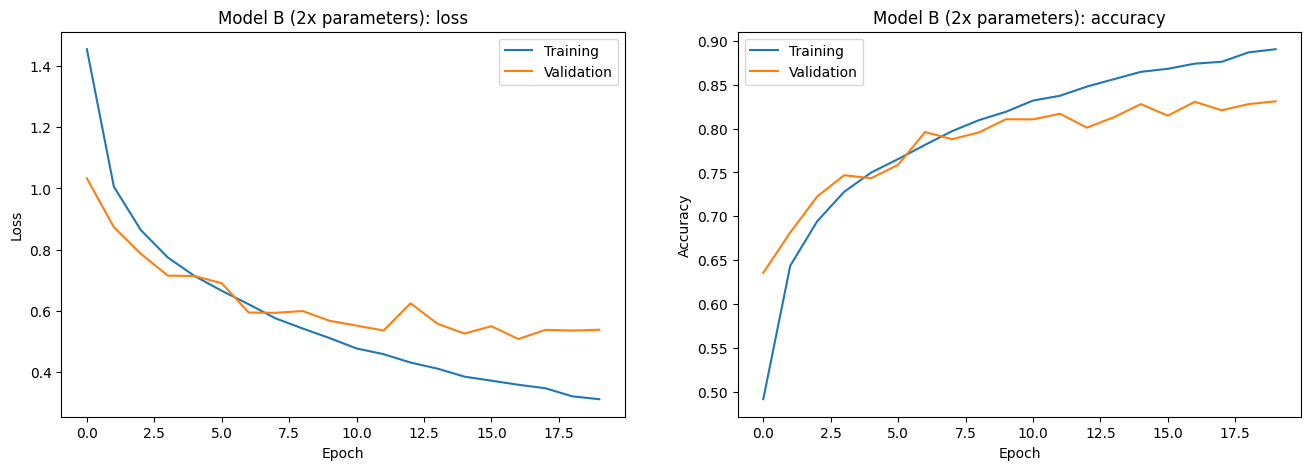

In [19]:
# Visualize the learning curves
##### YOUR CODE STARTS #####
plot_learning_curves(results_b['history'], 'Model B (2x parameters)')
##### YOUR CODE ENDS #####

In [20]:
# Report the properties
###### YOUR CODE STARTS #####
report(results_b)
##### YOUR CODE ENDS #####

Number of parameters: 1,457,746
Memory usage for the model parameters: 5.56 MB
Training time: 125.8 s (20 epochs, 6.3 s/epoch)
Inference time: 1.28 s for 10000 test images (0.128 ms/image)
Accuracy on the training set: 0.9534
Accuracy on the test set: 0.8244


<font color='red'> **(c)** Finally, create a third model with approximately the same number of parameters as the initial baseline model, but aim for accuracy that matches or even exceeds the second (larger) model. Report the same properties and visualize the learning curves for this model. (**1.5 points**)

HINT: To get higher accuracy, focus on applying techniques you have learned from the lecture and practice sessions.
</font>

In [21]:
##### YOUR CODE STARTS #####
# you might want to use several cells
# Model C: about the same number of parameters as the baseline, but used much more efficiently:
#  * VGG-style network: 3 blocks of two 3x3 convolutions (32 -> 64 -> 128 filters), all with BatchNorm + ReLU.
#    Convolutions share weights over the image, so they give a lot of "power" per parameter.
#  * 3 poolings shrink the feature map to 4x4, so the Flatten vector is small (2048) and the expensive
#    Dense layer needs much fewer weights (in the baseline almost all 730k parameters are in Dense(100) after Flatten).
#  * More dropout (0.2 / 0.3 / 0.4 / 0.5) against overfitting.
#  * Data augmentation (random horizontal flips and shifts, `train_aug_ds` defined in (a)) - the model sees
#    "new" images every epoch. It is done in the input pipeline, so it adds no parameters and is only used in training.
#  * Longer training (30 epochs) with learning rate reduction when the validation loss stops improving.
from keras.callbacks import ReduceLROnPlateau

keras.backend.clear_session()  # free memory used by the previous model
gc.collect()
keras.utils.set_random_seed(42)


def conv_bn_relu(t, filters):
    t = Conv2D(filters, (3, 3), padding="same")(t)
    return Activation('relu')(BatchNormalization()(t))


x = Input(shape=(32, 32, 3))
t = conv_bn_relu(x, 32)
t = conv_bn_relu(t, 32)
t = Dropout(rate=0.2)(MaxPooling2D(pool_size=2)(t))   # 16x16

t = conv_bn_relu(t, 64)
t = conv_bn_relu(t, 64)
t = Dropout(rate=0.3)(MaxPooling2D(pool_size=2)(t))   # 8x8

t = conv_bn_relu(t, 128)
t = conv_bn_relu(t, 128)
t = Dropout(rate=0.4)(MaxPooling2D(pool_size=2)(t))   # 4x4

f = Flatten()(t)
d = Dense(215)(f)
d = Activation('relu')(BatchNormalization()(d))
d = Dropout(rate=0.5)(d)
p = Activation('softmax')(Dense(10)(d))

model_c = Model(inputs=x, outputs=p)
model_c.compile(loss='sparse_categorical_crossentropy', optimizer=Adam(learning_rate=0.001), metrics=['accuracy'])
model_c.summary()
print(f"Parameter ratio C / A: {model_c.count_params() / results_a['params']:.2f}")

reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5, verbose=1)
results_c = train_and_measure('C', model_c, epochs=30, callbacks=[reduce_lr], train_data=train_aug_ds)
##### YOUR CODE ENDS #####

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 732,355 (2.79 MB)

 Trainable params: 731,029 (2.79 MB)

 Non-trainable params: 1,326 (5.18 KB)

Parameter ratio C / A: 1.00
Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


704/704 - 38s - 54ms/step - accuracy: 0.4172 - loss: 1.6261 - val_accuracy: 0.5598 - val_loss: 1.2289 - learning_rate: 0.0010
Epoch 2/30
704/704 - 7s - 10ms/step - accuracy: 0.5787 - loss: 1.1793 - val_accuracy: 0.6470 - val_loss: 0.9946 - learning_rate: 0.0010
Epoch 3/30
704/704 - 10s - 15ms/step - accuracy: 0.6402 - loss: 1.0164 - val_accuracy: 0.6748 - val_loss: 0.8849 - learning_rate: 0.0010
Epoch 4/30
704/704 - 7s - 10ms/step - accuracy: 0.6752 - loss: 0.9260 - val_accuracy: 0.7010 - val_loss: 0.8304 - learning_rate: 0.0010
Epoch 5/30
704/704 - 7s - 11ms/step - accuracy: 0.7020 - loss: 0.8601 - val_accuracy: 0.7260 - val_loss: 0.7713 - learning_rate: 0.0010
Epoch 6/30
704/704 - 7s - 11ms/step - accuracy: 0.7201 - loss: 0.8091 - val_accuracy: 0.7696 - val_loss: 0.6382 - learning_rate: 0.0010
Epoch 7/30
704/704 - 7s - 10ms/step - accuracy: 0.7339 - loss: 0.7702 - val_accuracy: 0.7814 - val_loss: 0.6315 - learning_rate: 0.0010
Epoch 8/30
704/704 - 10s - 15ms/step - accuracy: 0.7449 -

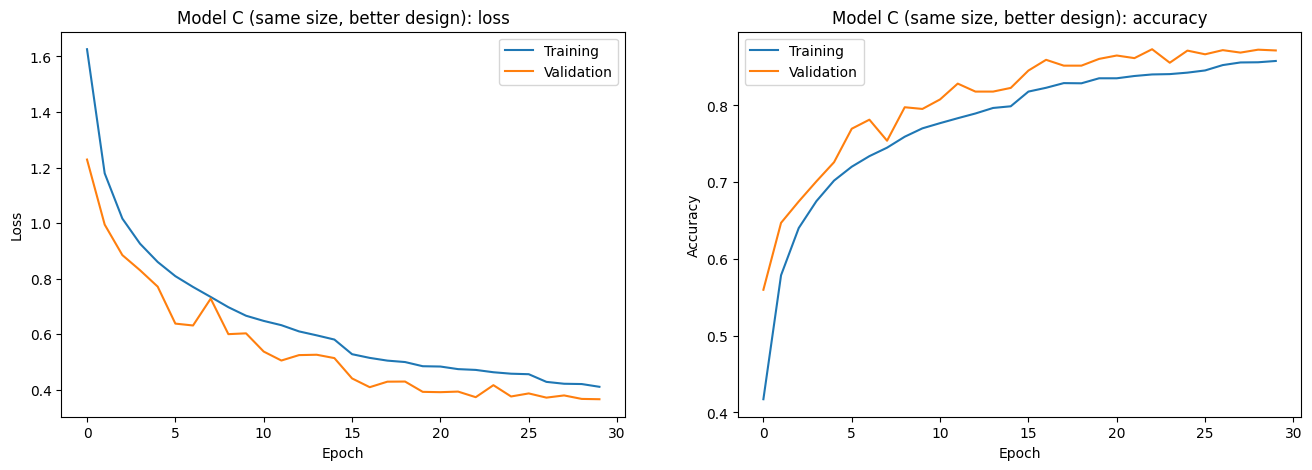

In [22]:
# Visualize the learning curves
##### YOUR CODE STARTS #####
plot_learning_curves(results_c['history'], 'Model C (same size, better design)')
##### YOUR CODE ENDS #####

In [23]:
# Report the properties
###### YOUR CODE STARTS #####
report(results_c)
##### YOUR CODE ENDS #####

Number of parameters: 732,355
Memory usage for the model parameters: 2.79 MB
Training time: 271.6 s (30 epochs, 9.1 s/epoch)
Inference time: 1.72 s for 10000 test images (0.172 ms/image)
Accuracy on the training set: 0.9078
Accuracy on the test set: 0.8767


<font color='red'> **(d)** Summarise all key properties (such as number of parameters and memory usage) of all three models in a single neat table! Also, additionally add a figure with all three pairs of learning curves (perhaps, using a different panel for each pair of curves). Explain how changes in the architecture affected the behaviour of all three models during training and inference. Which model would you choose for real-world use? Feel free to discuss different use cases. (**0.5 points**)
</font>

In [24]:
# (d) Summary table of all three models
all_results = {'A: baseline (practice)': results_a, 'B: 2x parameters': results_b, 'C: same size, improved': results_c}
summary = pd.DataFrame({
    name: {
        'Parameters': f"{r['params']:,}",
        'Params vs A': f"{r['params'] / results_a['params']:.2f}x",
        'Memory (MB)': f"{r['memory_mb']:.2f}",
        'Epochs': r['epochs'],
        'Training time (s)': f"{r['train_time']:.0f}",
        'Time / epoch (s)': f"{r['train_time'] / r['epochs']:.1f}",
        'Inference, 10k images (s)': f"{r['inference_time']:.2f}",
        'Inference / image (ms)': f"{1000 * r['inference_time'] / len(X_test_norm):.3f}",
        'Train accuracy': f"{r['train_acc']:.4f}",
        'Best val accuracy': f"{max(r['history']['val_accuracy']):.4f}",
        'Test accuracy': f"{r['test_acc']:.4f}",
        'Train - test gap': f"{r['train_acc'] - r['test_acc']:.4f}",
    } for name, r in all_results.items()
})
summary

,A: baseline (practice),B: 2x parameters,"C: same size, improved"
Parameters,"731,910","1,457,746","732,355"
Params vs A,1.00x,1.99x,1.00x
Memory (MB),2.79,5.56,2.79
Epochs,20,20,30
Training time (s),98,126,272
Time / epoch (s),4.9,6.3,9.1
"Inference, 10k images (s)",1.25,1.28,1.72
Inference / image (ms),0.125,0.128,0.172
Train accuracy,0.9226,0.9534,0.9078
Best val accuracy,0.7174,0.8310,0.8732


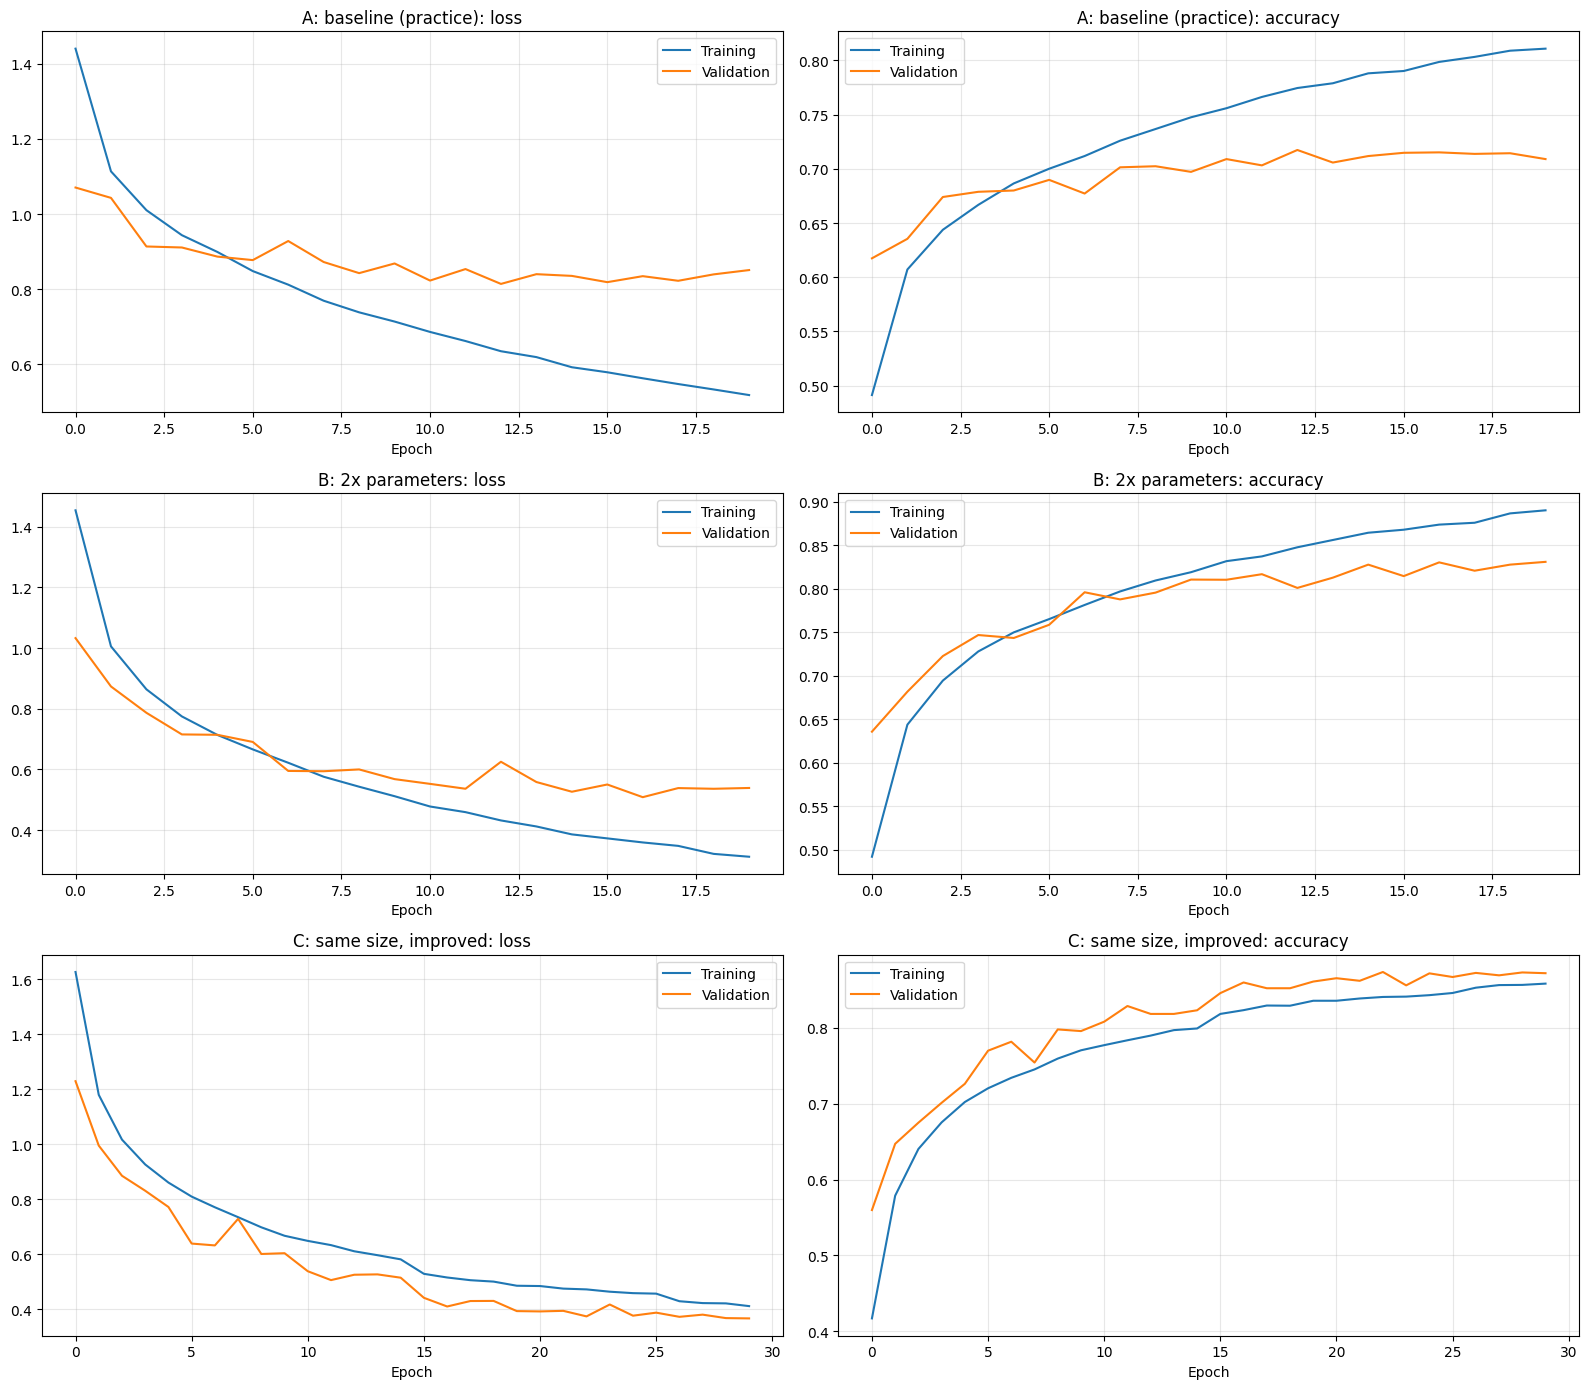

In [25]:
# (d) All learning curves in one figure: one row per model, loss on the left, accuracy on the right
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
for row, (name, r) in enumerate(all_results.items()):
    hist = r['history']
    axes[row, 0].plot(hist['loss'], label='Training')
    axes[row, 0].plot(hist['val_loss'], label='Validation')
    axes[row, 0].set_title(f'{name}: loss')
    axes[row, 1].plot(hist['accuracy'], label='Training')
    axes[row, 1].plot(hist['val_accuracy'], label='Validation')
    axes[row, 1].set_title(f'{name}: accuracy')
    for ax in axes[row]:
        ax.set_xlabel('Epoch')
        ax.legend()
        ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

<font color='red'>  Answer to **(d)**: </font>

*(exact numbers are in the table above; they change a bit from run to run)*

**Model A (baseline, ~0.73M parameters, ~2.8 MB).** Only two convolutional layers and one pooling, so the Flatten vector is huge (15·15·32 = 7200) and ~98% of all parameters sit in the single `Dense(100)` layer. The model is fast to train and to run, but it learns mostly "memorised" pixel patterns: the training accuracy keeps rising while the validation loss stops improving after a few epochs and then grows — a clear sign of **overfitting** with a large train–test gap. Test accuracy is the lowest of the three.

**Model B (~1.46M parameters, 2x, ~5.6 MB).** The second convolutional block gives the network more abstract features, so the test accuracy is clearly higher than A. However, doubling the size also doubles memory, and training/inference are slower (more convolutions with 64 filters). Most of the added parameters again went into the dense layer, which mainly increases the capacity to memorise — the validation curve flattens early and the gap between training and validation accuracy is still large. So "2x more parameters" gives only a moderate gain.

**Model C (~0.73M parameters, same as A, ~2.8 MB).** Same parameter budget, but used much better: deeper convolutional part (6 conv layers), three poolings → small Flatten vector, so the parameters go into convolutions instead of a giant dense layer; plus data augmentation, more dropout and LR reduction. The training curve is now *below* or close to the validation curve (augmentation and dropout make training harder), validation loss keeps decreasing for most of the training, and the train–test gap is the smallest → much better generalisation. It reaches the **highest test accuracy, better than the 2x larger model B**. The price is compute, not memory: 6 convolutions on full-resolution feature maps cost more FLOPs, so one epoch and the inference per image are slower than A, and we trained 1.5x more epochs, so the total training time is the longest.

**Main lesson:** the number of parameters by itself says little about accuracy — architecture (where the parameters are) and regularisation (augmentation, dropout, BN, LR schedule) matter more. Memory is determined by the parameter count, but speed is determined by the number of operations (convolutions on large feature maps).

**Which model to choose:**
* **General real-world use — Model C.** Best accuracy and the same small memory footprint as the baseline (fits easily on a phone or a microcontroller-class device); inference is still well under a millisecond per image on a GPU.
* **Extremely limited compute / need the fastest possible inference** (e.g. very weak CPU, huge throughput) — Model A, accepting a lower accuracy, or C with fewer filters.
* **Model B is the worst trade-off**: 2x memory and slower than A, yet less accurate than C — there is no use case where it is clearly the best choice.

## Homework exercise 3 (2 points): Create your own dataset and build a CNN model using fast.ai API
<font color='red'> In this exercise, you have a chance to test if CNN can distinguish between images of your favourite objects. </font>

In [3]:
# fast.ai v2 (the version installed in Colab) - same import as in the practice session
from fastai.vision.all import *
from fastai.metrics import error_rate

from pathlib import Path
from PIL import Image
import requests, io
import pandas as pd
from tqdm.auto import tqdm

import warnings
warnings.filterwarnings('ignore')

from urllib.request import urlopen

<font color='red'> **(a)** Create your own dataset with two or more classes using the same approach we used in the class. But this time choose classes yourself. **(1 point)** </font>

In [4]:
# In the practice session we collected the image URLs from Google Images with a JS snippet and uploaded the csv files here.
# Google Images is not reliable for automatic scraping, so instead the URL lists are collected below with the open
# iNaturalist API (photos of wild animals with community-verified species labels) and saved in the same csv format.
# If you prefer the practice-session way, set UPLOAD_CSV = True and upload lynx.csv / brown_bear.csv / moose.csv here.
UPLOAD_CSV = False
if UPLOAD_CSV:
    from google.colab import files
    uploaded = files.upload()
else:
    print("Skipping upload - URL lists are collected with the iNaturalist API in the next cell")

Skipping upload - URL lists are collected with the iNaturalist API in the next cell


In [5]:
##### YOUR CODE STARTS #####
from fastai.vision.all import *
from pathlib import Path
from PIL import Image
import requests, io
import pandas as pd
from tqdm.auto import tqdm

# My classes: three big animals of the Estonian forest - Eurasian lynx, brown bear and moose.
classes = {             # class name -> iNaturalist taxon id
    'lynx': 41979,          # Lynx lynx (Eurasian lynx)
    'brown_bear': 41641,    # Ursus arctos
    'moose': 522193,        # Alces alces
}
IMAGES_PER_CLASS = 150


def collect_urls(taxon_id, n, page=1):
    """Returns URLs of n research-grade photos of the given species from iNaturalist."""
    r = requests.get('https://api.inaturalist.org/v1/observations',
                     params=dict(taxon_id=taxon_id, photos='true', quality_grade='research',
                                 per_page=n, page=page, order_by='votes'),
                     timeout=30)
    r.raise_for_status()
    return [obs['photos'][0]['url'].replace('square', 'medium')   # 'medium' = ~500 px
            for obs in r.json()['results'] if obs.get('photos')]


if not UPLOAD_CSV:
    for name, taxon_id in classes.items():
        urls = collect_urls(taxon_id, IMAGES_PER_CLASS)
        pd.DataFrame({'url': urls}).to_csv(f'{name}.csv', index=False)
        print(f'{name}: {len(urls)} urls saved to {name}.csv')


# download function from the practice session
def download_images(csv_path, label='', max_images=10000, timeout=10):
  out_dir = Path('./data') / label

  out_dir.mkdir(parents=True, exist_ok=True)
  df = pd.read_csv(csv_path)

  max_images = min(max_images, len(df))
  df = df.head(max_images)

  for i, row in tqdm(df.iterrows(), total=len(df), desc="Downloading"):
    url = row.iloc[0]
    try:
      r = requests.get(url, timeout=timeout)
      r.raise_for_status()
      img = Image.open(io.BytesIO(r.content)).convert("RGB")
      fname = out_dir / f"{i}.jpg"
      if not fname.exists():
          img.save(fname, format="JPEG", quality=90)
    except Exception as e:
          print("Broken url", url, "->", e)

  print(f"\nDataset ready!")


for name in classes:
    download_images(f'{name}.csv', label=name, max_images=IMAGES_PER_CLASS)
##### YOUR CODE ENDS #####

lynx: 150 urls saved to lynx.csv
brown_bear: 150 urls saved to brown_bear.csv
moose: 150 urls saved to moose.csv


Downloading:   0%|          | 0/150 [00:00<?, ?it/s]


Dataset ready!


Downloading:   0%|          | 0/150 [00:00<?, ?it/s]


Dataset ready!


Downloading:   0%|          | 0/150 [00:00<?, ?it/s]


Dataset ready!


lynx 150 images
brown_bear 150 images
moose 150 images
['brown_bear', 'lynx', 'moose'] 360 train / 90 validation images


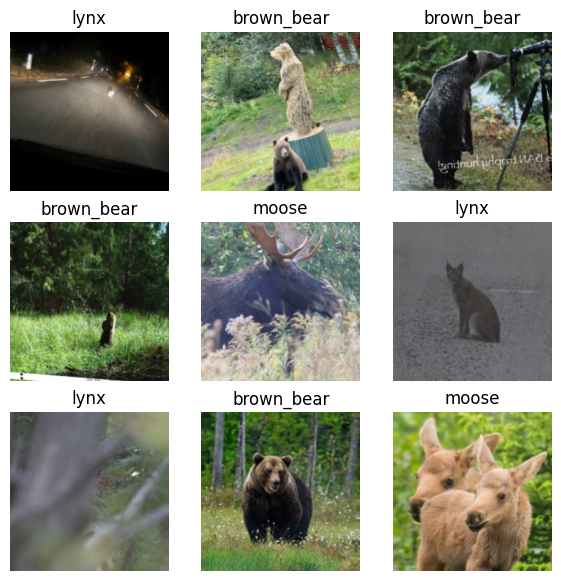

In [6]:
# add more cells as necessary
from fastai.vision.all import *
from pathlib import Path
from PIL import Image
import requests, io
import pandas as pd
from tqdm.auto import tqdm

# remove images that cannot be opened or are too small (same as in the practice session)
def verify_image(fn, min_width, min_height):
  try:
    im = Image.open(fn)
    im.load()
    width, height = im.size
    return width >= min_width and height >= min_height
  except Exception as e:
    print(e)
    return False


path = Path('data')
for c in classes:
    for img_file in get_image_files(path/c):
        if not verify_image(img_file, 100, 100):
            print(f"Corrupted image found and deleted: {img_file}")
            img_file.unlink()
    print(c, len(get_image_files(path/c)), 'images')

dls = ImageDataLoaders.from_folder(path, valid_pct=0.2, seed=42, item_tfms=Resize(224), batch_tfms=aug_transforms())
print(dls.vocab, len(dls.train_ds), 'train /', len(dls.valid_ds), 'validation images')
dls.show_batch(max_n=9, figsize=(7, 7))

<font color='red'> **(b)** train a neural network on images you have acquired **(0.5 points)** </font>

In [7]:
##### YOUR CODE STARTS #####
learn = vision_learner(dls, resnet34, metrics=[accuracy, error_rate])
learn.fine_tune(4)  # 1 epoch with frozen pretrained body, then 4 epochs of the whole network
##### YOUR CODE ENDS #####

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 189MB/s]


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.589182,0.301201,0.844444,0.155556,00:03


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.760074,0.149948,0.933333,0.066667,00:03
1,0.610296,0.162413,0.888889,0.111111,00:03
2,0.488540,0.220785,0.900000,0.100000,00:02
3,0.395527,0.228323,0.888889,0.111111,00:02


Plot the confusion matrix to make sure that you model has learned something:

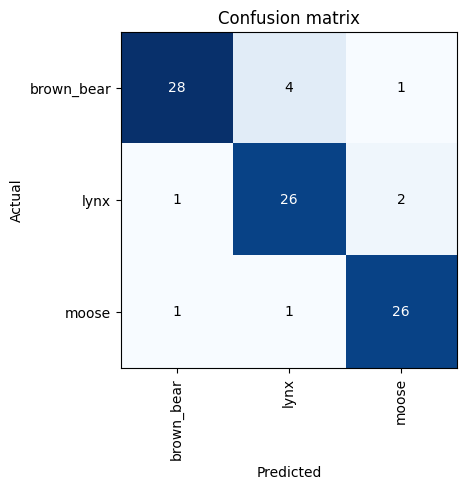

In [8]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

<font color='red'> **(c)** Test your model on one or more images from the internet that represent classes you have chosen, but unlikely to be in the training data (you can change your search query). Print out class probabilities for one of these test images. **(0.5 points)** </font>

true: lynx       predicted: brown_bear probability 0.730


true: brown_bear predicted: brown_bear probability 1.000


true: moose      predicted: moose      probability 1.000


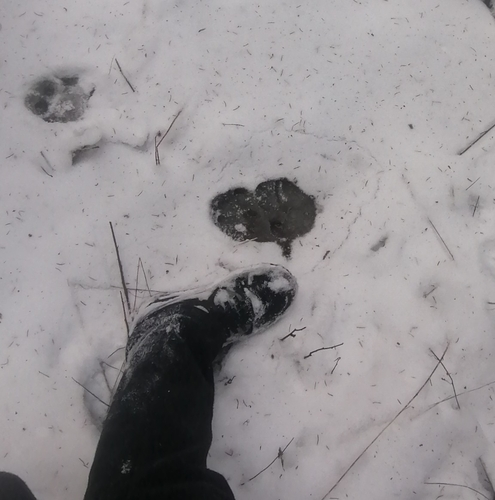

In [9]:
##### YOUR CODE STARTS #####
# Test images: photos from a much later page of the iNaturalist results (training used only the first 150 results),
# so they are not in the training data.
test_urls = {name: collect_urls(taxon_id, 5, page=100)[0] for name, taxon_id in classes.items()}
train_urls = set(pd.concat([pd.read_csv(f'{n}.csv') for n in classes])['url'])
assert not set(test_urls.values()) & train_urls, "test image is in the training data"

test_images = {name: PILImage.create(io.BytesIO(requests.get(url, timeout=20).content))
               for name, url in test_urls.items()}
for name, im in test_images.items():
    pred_class, pred_idx, outputs = learn.predict(im)
    print(f"true: {name:10s} predicted: {pred_class:10s} probability {outputs[pred_idx]:.3f}")

img = test_images['lynx']
img
##### YOUR CODE ENDS #####

In [10]:
# What are the probabilities of different classes for this image?
##### YOUR CODE STARTS #####
pred_class, pred_idx, outputs = learn.predict(img)
print('Predicted class:', pred_class)
for cls, prob in zip(learn.dls.vocab, outputs):
    print(f'P({cls}) = {prob:.4f}')
##### YOUR CODE ENDS #####

Predicted class: brown_bear
P(brown_bear) = 0.7299
P(lynx) = 0.2478
P(moose) = 0.0223


# Bonus exercises
*(NB, these are optional exercises!)*

## Bonus exercise 1 (2 bonus points):

<font color='red'> [Stable Diffusion](https://stability.ai/blog/stable-diffusion-announcement) model has been recently shown to produce trully impressive results in image generation. Let's explore some of its power in this auxiliarly exercise. Use Stable Diffusion model from this [colab](https://colab.research.google.com/github/huggingface/notebooks/blob/main/diffusers/stable_diffusion.ipynb?hl=en). Generate several tricky images to test the model you trained in the exercise 3. Report the images that you have generated with Stable Diffusion, prompt that you have used for generating them, the number of iterations that you used to generate images and the classification results from your CNN model. Shortly summarise the results you have obtained. </font>

In [11]:
# Bonus 1: generate tricky images with Stable Diffusion (same pipeline as in the linked colab)
!pip install -q diffusers transformers accelerate
import torch
from diffusers import StableDiffusionPipeline

sd_pipe = StableDiffusionPipeline.from_pretrained("CompVis/stable-diffusion-v1-4", torch_dtype=torch.float16)
sd_pipe = sd_pipe.to("cuda")

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

Prompt: "a cartoon drawing of a lynx with tufted ears, children's book illustration"
  intended: lynx -> predicted: moose (brown_bear: 0.00, lynx: 0.07, moose: 0.92)


Prompt: "a brown teddy bear toy sitting in a dark forest, photo"
  intended: brown_bear -> predicted: brown_bear (brown_bear: 0.87, lynx: 0.05, moose: 0.08)


Prompt: "an origami moose made of brown paper on a table, macro photo"
  intended: moose -> predicted: moose (brown_bear: 0.00, lynx: 0.16, moose: 0.84)


Prompt: "a domestic house cat with long ear tufts sitting in the snow, photo"
  intended: lynx -> predicted: lynx (brown_bear: 0.01, lynx: 0.99, moose: 0.00)


Prompt: "a brown bear wearing moose antlers, photo"
  intended: brown_bear -> predicted: moose (brown_bear: 0.01, lynx: 0.00, moose: 0.98)


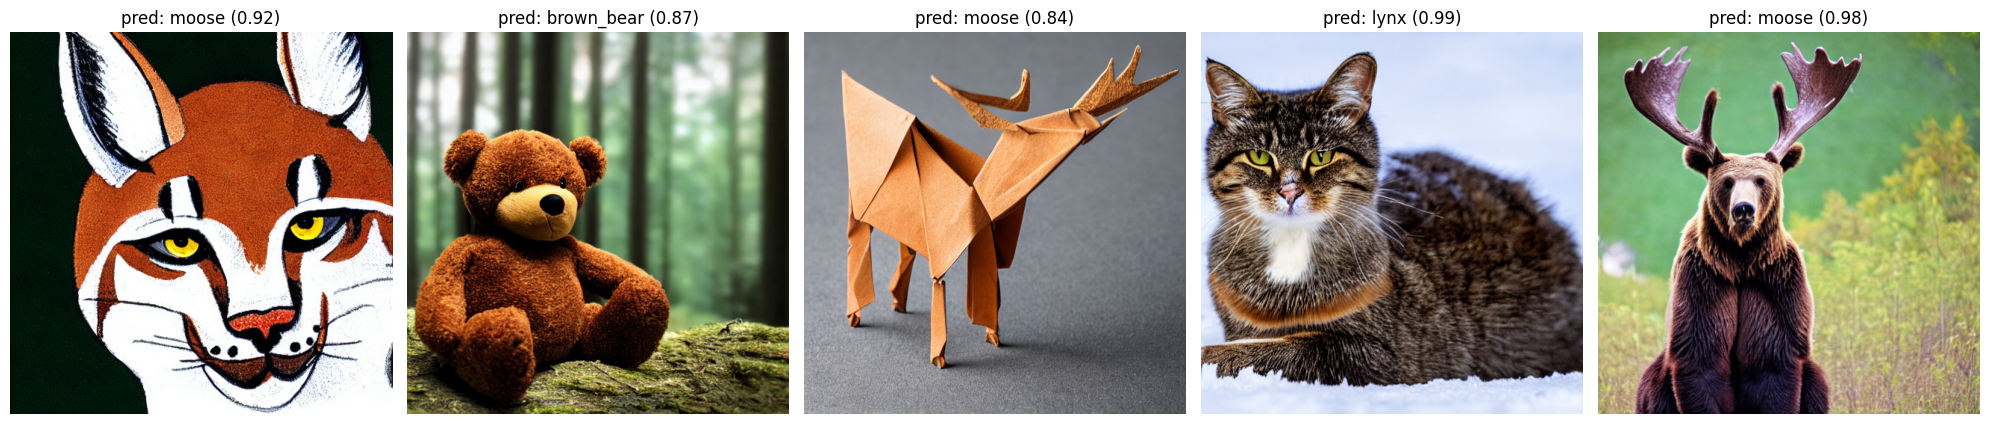

In [12]:
NUM_STEPS = 50  # number of denoising iterations
prompts = [  # (class the image is meant to look like, prompt)
    ('lynx',       "a cartoon drawing of a lynx with tufted ears, children's book illustration"),
    ('brown_bear', "a brown teddy bear toy sitting in a dark forest, photo"),
    ('moose',      "an origami moose made of brown paper on a table, macro photo"),
    ('lynx',       "a domestic house cat with long ear tufts sitting in the snow, photo"),
    ('brown_bear', "a brown bear wearing moose antlers, photo"),
]

generator = torch.Generator("cuda").manual_seed(0)
sd_images = [sd_pipe(p, num_inference_steps=NUM_STEPS, generator=generator).images[0] for _, p in prompts]

fig, axes = plt.subplots(1, len(sd_images), figsize=(4 * len(sd_images), 5))
for ax, (intended, prompt), im in zip(axes, prompts, sd_images):
    pred_class, pred_idx, outputs = learn.predict(PILImage.create(np.array(im)))
    probs = ', '.join(f'{c}: {p:.2f}' for c, p in zip(learn.dls.vocab, outputs))
    print(f'Prompt: "{prompt}"\n  intended: {intended} -> predicted: {pred_class} ({probs})')
    ax.imshow(im)
    ax.set_title(f'pred: {pred_class} ({outputs[pred_idx]:.2f})')
    ax.axis('off')
plt.tight_layout()
plt.show()

**Bonus 1 summary:** We generated 5 images with Stable Diffusion v1-4 (50 denoising iterations each, seed 0) using prompts that are "tricky" for a model trained only on real wildlife photos: a cartoon lynx, a teddy bear, an origami moose, a house cat with ear tufts, and a bear with moose antlers. The prompts, the generated images and the predicted class probabilities are printed above. The classifier handles the stylised but clearly drawn animals reasonably well, because the shape cues (ear tufts, antlers, bear body) are still present. It is much less reliable on images that are out of its "world": the teddy bear and the house cat are not lynx/bear/moose at all, but the model must still pick one of its 3 classes and often does so with high confidence (softmax always sums to 1, there is no "other" class). The bear with antlers shows that the network relies on single strong features (antlers → moose). So a closed-set classifier is confident even when it should not be, which is an important limitation for real use.

## Bonus exercise 2 (2 bonus points):

<font color='red'> [Pytorch](https://pytorch.org/) is another widely used and deeply loved deep learning library. In this task, you will get a chance to try it out. Firstly, re-implement one of the CNNs you were working with in EX 2 (or you can try a different architecture) in Pytorch. Train and validate the model on the dataset you collected in EX3. Secondly, use a ResNet model from [torchhub](https://pytorch.org/docs/stable/hub.html) and train it on the same data. Compare the results of these two models and the one from fastai library.

In [13]:
# Bonus 2: PyTorch. Same data as in Ex3 (folder ./data), same 80/20 split idea.
import torch, torch.nn as nn, torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(42)

imagenet_norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

def make_loaders(size):
    train_tf = transforms.Compose([transforms.RandomResizedCrop(size, scale=(0.7, 1.0)), transforms.RandomHorizontalFlip(),
                                   transforms.ToTensor(), imagenet_norm])
    valid_tf = transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor(), imagenet_norm])
    full_train = datasets.ImageFolder('data', transform=train_tf)
    full_valid = datasets.ImageFolder('data', transform=valid_tf)
    idx = torch.randperm(len(full_train), generator=torch.Generator().manual_seed(42))
    n_valid = int(0.2 * len(idx))
    train_ds, valid_ds = Subset(full_train, idx[n_valid:].tolist()), Subset(full_valid, idx[:n_valid].tolist())
    return (DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2),
            DataLoader(valid_ds, batch_size=64, num_workers=2), full_train.classes)


def run_training(model, train_dl, valid_dl, epochs, lr):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    hist = []
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
        model.eval()
        correct = total = 0
        with torch.no_grad():
            for xb, yb in valid_dl:
                pred = model(xb.to(device)).argmax(1).cpu()
                correct += (pred == yb).sum().item()
                total += len(yb)
        hist.append(correct / total)
        print(f'epoch {epoch + 1}: last batch loss {loss.item():.3f}, validation accuracy {hist[-1]:.3f}')
    return hist

In [14]:
# 1) The improved CNN from Ex2 (model C) re-implemented in PyTorch, for 64x64 images (trained from scratch)
def conv_block(c_in, c_out, drop):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
        nn.MaxPool2d(2), nn.Dropout(drop))

train_dl64, valid_dl64, torch_classes = make_loaders(64)
cnn = nn.Sequential(
    conv_block(3, 32, 0.2), conv_block(32, 64, 0.3), conv_block(64, 128, 0.4),   # 64 -> 8x8
    nn.Flatten(), nn.Linear(128 * 8 * 8, 215), nn.BatchNorm1d(215), nn.ReLU(), nn.Dropout(0.5),
    nn.Linear(215, len(torch_classes)))
print('classes:', torch_classes, '| parameters:', sum(p.numel() for p in cnn.parameters()))
cnn_hist = run_training(cnn, train_dl64, valid_dl64, epochs=25, lr=1e-3)

classes: ['brown_bear', 'lynx', 'moose'] | parameters: 2050477
epoch 1: last batch loss 1.140, validation accuracy 0.322
epoch 2: last batch loss 0.914, validation accuracy 0.389
epoch 3: last batch loss 1.144, validation accuracy 0.456
epoch 4: last batch loss 0.918, validation accuracy 0.367
epoch 5: last batch loss 0.715, validation accuracy 0.567
epoch 6: last batch loss 0.984, validation accuracy 0.533
epoch 7: last batch loss 1.090, validation accuracy 0.544
epoch 8: last batch loss 1.035, validation accuracy 0.478
epoch 9: last batch loss 1.006, validation accuracy 0.544
epoch 10: last batch loss 0.777, validation accuracy 0.511
epoch 11: last batch loss 0.866, validation accuracy 0.467
epoch 12: last batch loss 1.118, validation accuracy 0.556
epoch 13: last batch loss 0.804, validation accuracy 0.511
epoch 14: last batch loss 0.466, validation accuracy 0.456
epoch 15: last batch loss 0.560, validation accuracy 0.522
epoch 16: last batch loss 0.677, validation accuracy 0.556
ep

In [15]:
# 2) ResNet-18 from torch hub, pretrained on ImageNet, last layer replaced for our classes (fine-tuning)
train_dl224, valid_dl224, _ = make_loaders(224)
resnet = torch.hub.load('pytorch/vision', 'resnet18', weights='IMAGENET1K_V1')
resnet.fc = nn.Linear(resnet.fc.in_features, len(torch_classes))
resnet_hist = run_training(resnet, train_dl224, valid_dl224, epochs=5, lr=1e-4)

Downloading: "https://github.com/pytorch/vision/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 90.6MB/s]


epoch 1: last batch loss 0.910, validation accuracy 0.844
epoch 2: last batch loss 0.097, validation accuracy 0.822
epoch 3: last batch loss 0.172, validation accuracy 0.844
epoch 4: last batch loss 0.043, validation accuracy 0.844
epoch 5: last batch loss 0.196, validation accuracy 0.833


In [16]:
# Comparison with the fast.ai model from Ex3
fastai_acc = float(learn.validate()[1])
comparison = pd.DataFrame({
    'Model': ['PyTorch CNN from scratch (model C style, 64x64)', 'PyTorch ResNet-18 (torch hub, pretrained)', 'fast.ai ResNet-34 (pretrained, Ex3)'],
    'Validation accuracy': [f'{cnn_hist[-1]:.3f}', f'{resnet_hist[-1]:.3f}', f'{fastai_acc:.3f}'],
})
comparison

,Model,Validation accuracy
0,"PyTorch CNN from scratch (model C style, 64x64)",0.522
1,"PyTorch ResNet-18 (torch hub, pretrained)",0.833
2,"fast.ai ResNet-34 (pretrained, Ex3)",0.889


**Bonus 2 summary:** The small CNN trained from scratch has to learn everything from only ~360 training images, so it overfits quickly and its validation accuracy stays clearly below the two pretrained models. Both pretrained ResNets (PyTorch ResNet-18 from torch hub and fast.ai ResNet-34) reach a much higher accuracy after just a few epochs, because they reuse features learned on ImageNet (which already contains animals) — transfer learning is the key for small datasets. PyTorch needs much more code (data loaders, training loop, evaluation) than fast.ai, where the same result is a few lines, but in exchange it gives full control over every step. Exact numbers are in the table above.

# Comments (optional feedback to the course instructors)
Here, please, leave your comments regarding the homework, possibly answering the following questions:
* how much time did you spend on this homework?
* was it too hard/easy for you?
* what would you suggest to add or remove?
* anything else you would like to tell us

Your comments:

# <font color='red'>  End of the homework. Please don't delete this cell.</font>